# CECS 385 — Quantum vs. Classical Portfolio Selection (20 ETFs)

**Question:** When given the same AI return forecasts and risk estimates, how close does QAOA get to the exact classical optimum when selecting **3 of 20 ETFs**?

- **AI:** Random Forest estimates next-month ETF returns using data available through December 2024.
- **Classical:** Check all **1,140** combinations, plus a greedy baseline.
- **Quantum:** QAOA with 20 qubits, a constraint-preserving XY mixer, and Qiskit Aer.
- **Out-of-sample check:** Compare the chosen portfolios' *actual January 2025 returns* (one month is not enough for Sharpe ratio conclusions).

**Important:** A QAOA simulator is not real quantum hardware. Exhaustive search is guaranteed to match or exceed QAOA on the **same estimated score**. The purpose is to measure QAOA's accuracy and computation cost.

Run in **Google Colab** from top to bottom. The QAOA step can be relatively slow with 20 qubits.

## 1. Install packages

In [4]:
%pip -q install qiskit qiskit-aer yfinance scikit-learn pandas numpy matplotlib scipy


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Settings
`QUICK_TEST = True` uses fewer optimization iterations. For a more meaningful experiment, switch it to `False` after the first successful run. Both settings still use **20 ETFs**.

In [5]:
import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.ensemble import RandomForestRegressor
from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
url = "https://raw.githubusercontent.com/manisahni/marketdata/main/daily_adjclose.csv"
TICKERS = [
    "XLK", "XLV", "XLF", "XLE", "XLI", "XLP", "XLU", "XLB", "XLY", "XLC",
    "IWM", "EFA", "EEM", "TLT", "IEF", "GLD", "SLV", "VNQ", "TIP", "HYG"
]
# XLC started in 2018, so training is limited to 2018 onward for a complete 20-ETF sample.
CHOOSE = 3
LAMBDA = 1.0
QUICK_TEST = True
SHOTS = 128 if QUICK_TEST else 1024
MAX_ITER = 12 if QUICK_TEST else 75
DEPTH = 1 if QUICK_TEST else 2
SEED = 7
CIRCUIT_SCALE = 100.0  # magnifies small decimal return scores for quantum phase gates

print("ETFs:", len(TICKERS), " | portfolios:", len(list(itertools.combinations(TICKERS, CHOOSE))))

ETFs: 20  | portfolios: 1140


## 3. Download prices and prepare Random Forest forecasts

Prices are adjusted for splits and distributions. The forecasting features at a given month end use **past months only**. The target is the *next month's* return. Models train only on historical observations whose target is known by December 2024. January 2025 is reserved for checking realized performance.

This uses Yahoo Finance through `yfinance`, not the original GitHub CSV. If downloads fail, rerun the cell or use a saved adjusted-price CSV with the same ticker columns.

In [6]:
raw = yf.download(TICKERS, start="2017-01-01", end="2025-02-01", auto_adjust=True, progress=False, threads=True)
if raw.empty:
    raise RuntimeError("Yahoo Finance returned no prices. Try rerunning in Colab.")

prices = raw["Close"][TICKERS].copy()
prices = prices.ffill()  # fill occasional missing trading-day entries after a fund's inception
monthly = prices.resample("ME").last()
monthly = monthly.loc["2019-01-31":"2025-01-31"]

if monthly.loc["2020-01-31":"2025-01-31", TICKERS].isna().any().any():
    raise ValueError("Missing ETF data in analysis period. Check ticker download and dates.")

monthly_returns = monthly.pct_change(fill_method=None)
features = {}
for ticker in TICKERS:
    r = monthly_returns[ticker]
    features[ticker] = pd.DataFrame({
        "last_month": r,
        "last_3_months": monthly[ticker].pct_change(3),
        "last_6_months": monthly[ticker].pct_change(6),
        "volatility_3m": r.rolling(3).std(),
        "next_month": r.shift(-1)
    }).dropna()

predictions = []
for ticker in TICKERS:
    df = features[ticker]
    train = df.loc[df.index <= "2024-11-30"]
    current_features = df.drop(columns="next_month", errors="ignore")
    # The forecast row has no next_month target yet, so take it from the full feature calculation instead.
    r = monthly_returns[ticker]
    forecast_row = pd.DataFrame({
        "last_month": r,
        "last_3_months": monthly[ticker].pct_change(3),
        "last_6_months": monthly[ticker].pct_change(6),
        "volatility_3m": r.rolling(3).std()
    }).loc[[pd.Timestamp("2024-12-31")]]
    if len(train) < 24 or forecast_row.isna().any().any():
        raise ValueError(f"Not enough clean training data for {ticker}")
    columns = ["last_month", "last_3_months", "last_6_months", "volatility_3m"]
    model = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=SEED)
    model.fit(train[columns], train["next_month"])
    predictions.append(float(model.predict(forecast_row[columns])[0]))

mu = np.array(predictions)  # predicted January 2025 monthly returns
# 36 months of history, ending Dec 2024; covariance is monthly, just like mu.
cov = monthly_returns.loc["2022-01-31":"2024-12-31", TICKERS].cov().values
actual_jan = monthly_returns.loc[pd.Timestamp("2025-01-31"), TICKERS].values
assert np.isfinite(mu).all() and np.isfinite(cov).all()

print(pd.DataFrame({"ETF": TICKERS, "Predicted Jan return": mu, "Actual Jan return": actual_jan}).round(4).to_string(index=False))

ETF  Predicted Jan return  Actual Jan return
XLK                0.0355            -0.0074
XLV                0.0328             0.0676
XLF                0.0463             0.0650
XLE                0.0552             0.0231
XLI               -0.0085             0.0500
XLP                0.0128             0.0047
XLU                0.0373             0.0289
XLB               -0.0124             0.0553
XLY               -0.0007             0.0349
XLC                0.0281             0.0575
IWM                0.0235             0.0250
EFA               -0.0201             0.0480
EEM               -0.0140             0.0215
TLT               -0.0085             0.0049
IEF                0.0065             0.0062
GLD                0.0040             0.0679
SLV                0.0338             0.0828
VNQ               -0.0049             0.0165
TIP                0.0028             0.0137
HYG                0.0099             0.0136


## 4. Same portfolio scoring formula for every optimizer

Equal-weight portfolio with exactly 3 ETFs:

\[	ext{Score}(x)=\mu^T w-\lambda w^T\Sigma w, \qquad w=x/3.\]

This is an **estimated objective score**, not a prediction of guaranteed realized profit. `LAMBDA = 1.0` is a research setting and can be varied later.

In [7]:
def portfolio_score(indices):
    ids = list(indices)
    w = np.zeros(len(TICKERS))
    w[ids] = 1 / CHOOSE
    return float(mu @ w - LAMBDA * (w @ cov @ w))

def portfolio_names(indices):
    return [TICKERS[i] for i in indices]

start = time.perf_counter()
all_portfolios = list(itertools.combinations(range(len(TICKERS)), CHOOSE))
scores = np.array([portfolio_score(p) for p in all_portfolios])
best_i = int(np.argmax(scores))
classical_choice = all_portfolios[best_i]
classical_score = float(scores[best_i])
classical_time = time.perf_counter() - start

# Greedy: add whichever ETF gives the best immediate total score until three are selected.
start = time.perf_counter()
greedy_choice = []
while len(greedy_choice) < CHOOSE:
    candidates = [i for i in range(len(TICKERS)) if i not in greedy_choice]
    greedy_choice.append(max(candidates, key=lambda i: portfolio_score(greedy_choice + [i])))
greedy_choice = tuple(sorted(greedy_choice))
greedy_time = time.perf_counter() - start

print("Classical:", portfolio_names(classical_choice), "score:", round(classical_score, 6))
print("Greedy:   ", portfolio_names(greedy_choice), "score:", round(portfolio_score(greedy_choice), 6))
print("Total combinations:", len(all_portfolios))

Classical: ['XLF', 'XLE', 'XLU'] score: 0.043425
Greedy:    ['XLF', 'XLE', 'XLU'] score: 0.043425
Total combinations: 1140


## 5. QAOA with a three-ETF constraint

The initial bitstring has exactly three selected ETFs. The **XY mixer** moves selections between neighboring qubits while preserving the number of selected ETFs. Consequently, sampled bitstrings should always select three ETFs (apart from numerical/transpilation issues).

`RZ`, `RZZ`, `RXX`, and `RYY` gates encode the portfolio score and enable mixing. This example deliberately uses a simple, student-readable circuit. It isn't a claim of quantum speedup.

**Practical warning:** 20 simulated qubits with many two-qubit gates can take considerable time. Quick mode uses `p=1`, 128 shots and 12 COBYLA iterations as a *smoke test*, not a reliable performance estimate.

In [8]:
# Score = sum(a[i] * x[i]) + sum(b[i,j] * x[i] * x[j]) for equal weights
N = len(TICKERS)
a = mu / CHOOSE - LAMBDA * np.diag(cov) / (CHOOSE ** 2)
b = np.zeros((N, N))
for i in range(N):
    for j in range(i+1, N):
        b[i, j] = -2 * LAMBDA * cov[i, j] / (CHOOSE ** 2)

# Start with three spread-out ETFs, rather than choosing the optimum in advance.
start_bits = [0, 7, 14]

# Use alternating nearest-neighbor XY layers on a ring, avoiding expensive generic matrix gates.
def build_circuit(gammas, betas):
    qc = QuantumCircuit(N)
    for i in start_bits:
        qc.x(i)

    for gamma, beta in zip(gammas, betas):
        # exp(+i gamma * score) up to a global phase.
        for i in range(N):
            angle = CIRCUIT_SCALE * gamma * (a[i] + 0.5 * sum(b[min(i,j), max(i,j)] for j in range(N) if j != i))
            qc.rz(angle, i)
        for i in range(N):
            for j in range(i + 1, N):
                if abs(b[i, j]) > 1e-12:
                    qc.rzz(-CIRCUIT_SCALE * gamma * b[i, j] / 2, i, j)

        # Every gate commutes with total excitation number (number of 1s).
        for offset in (0, 1):
            for i in range(offset, N - 1, 2):
                qc.rxx(beta, i, i + 1)
                qc.ryy(beta, i, i + 1)
        qc.rxx(beta, N - 1, 0)
        qc.ryy(beta, N - 1, 0)

    qc.measure_all()
    return qc

simulator = AerSimulator(method="matrix_product_state")

def sample_qaoa(theta, shots=SHOTS):
    gammas = theta[:DEPTH]
    betas = theta[DEPTH:]
    circuit = build_circuit(gammas, betas)
    # Reverse bits: Qiskit strings are displayed highest qubit index first.
    result = simulator.run(transpile(circuit, simulator, optimization_level=1), shots=shots, seed_simulator=SEED).result()
    counts = result.get_counts()
    scored = []
    for bitstring, count in counts.items():
        ids = tuple(i for i, bit in enumerate(bitstring[::-1]) if bit == "1")
        if len(ids) == CHOOSE:
            scored.append((ids, count, portfolio_score(ids)))
    return scored

calls = [0]
def loss(theta):
    result = sample_qaoa(theta)
    calls[0] += 1
    if not result:
        return 1e4
    total = sum(count for _, count, _ in result)
    return -sum(count * score for _, count, score in result) / total

initial = np.r_[np.full(DEPTH, 0.8), np.full(DEPTH, 0.5)]
start = time.perf_counter()
optimization = minimize(loss, initial, method="COBYLA", options={"maxiter": MAX_ITER, "rhobeg": 0.4})
qaoa_time = time.perf_counter() - start

# Evaluate a larger final sample and choose the best feasible portfolio observed.
final_samples = sample_qaoa(optimization.x, shots=max(1024, SHOTS))
if not final_samples:
    raise RuntimeError("QAOA produced no valid 3-ETF portfolios.")
quantum_choice, _, quantum_score = max(final_samples, key=lambda row: row[2])
valid_shots = sum(count for _, count, _ in final_samples)

print("QAOA:     ", portfolio_names(quantum_choice))
print("QAOA score:", round(quantum_score, 6))
print("Exact optimum:", round(classical_score, 6))
print("Absolute gap:", round(classical_score - quantum_score, 6))
print("Found optimum:", np.isclose(quantum_score, classical_score, atol=1e-10))
print("Valid sampled shots:", valid_shots)
print("Optimizer calls:", calls[0])
print("QAOA runtime (seconds):", round(qaoa_time, 2))

QAOA:      ['XLF', 'XLU', 'SLV']
QAOA score: 0.036882
Exact optimum: 0.043425
Absolute gap: 0.006543
Found optimum: False
Valid sampled shots: 1024
Optimizer calls: 12
QAOA runtime (seconds): 0.83


In [11]:
def run_qaoa_trial(seed, depth=1, max_iter=30):

    rng = np.random.default_rng(seed)
    sim = AerSimulator(method="matrix_product_state")

    # Different starting parameters for every run
    starting = rng.uniform(0, 2 * np.pi, depth * 2)

    def sample(theta, shots):

        gammas = theta[:depth]
        betas = theta[depth:]

        qc = build_circuit(gammas, betas)
        qc = transpile(qc, sim, optimization_level=1)

        result = sim.run(
            qc,
            shots=shots,
            seed_simulator=seed
        ).result()

        return result.get_counts()

    def loss(theta):

        counts = sample(theta, 128)

        total = 0
        valid = 0

        for bits, count in counts.items():

            selected = tuple(
                i for i, bit in enumerate(bits[::-1])
                if bit == "1"
            )

            if len(selected) == CHOOSE:
                total += portfolio_score(selected) * count
                valid += count

        if valid == 0:
            return 10000

        return -total / valid

    start = time.perf_counter()

    result = minimize(
        loss,
        starting,
        method="COBYLA",
        options={"maxiter": max_iter}
    )

    counts = sample(result.x, 1024)

    best_score = -np.inf
    best_portfolio = None
    valid_shots = 0

    for bits, count in counts.items():

        selected = tuple(
            i for i, bit in enumerate(bits[::-1])
            if bit == "1"
        )

        if len(selected) == CHOOSE:

            valid_shots += count
            s = portfolio_score(selected)

            if s > best_score:
                best_score = s
                best_portfolio = selected

    seconds = time.perf_counter() - start

    if best_portfolio is None:
        best_score = np.nan

    return {
        "seed": seed,
        "depth": depth,
        "score": best_score,
        "gap": classical_score - best_score,
        "found_optimum": (
            best_portfolio is not None
            and np.isclose(best_score, classical_score, atol=1e-8)
        ),
        "runtime": seconds,
        "valid_shots": valid_shots,
        "optimizer_calls": result.nfev,
        "portfolio": (
            ", ".join(portfolio_names(best_portfolio))
            if best_portfolio is not None else "None"
        )
    }

## 6. Compare the methods and check actual January 2025 returns

**Note:** One month of realized return is only an illustration, not proof that an algorithm will produce better investment results. The estimated optimization score is the proper primary comparison for this one-period study.

         Method          ETFs    Score  Seconds  Jan 2025 return  Gap from exact
Classical exact XLF, XLE, XLU 0.043425 0.006479         0.039006        0.000000
         Greedy XLF, XLE, XLU 0.043425 0.000515         0.039006        0.000000
   Quantum QAOA XLF, XLU, SLV 0.036882 0.830398         0.058900        0.006543


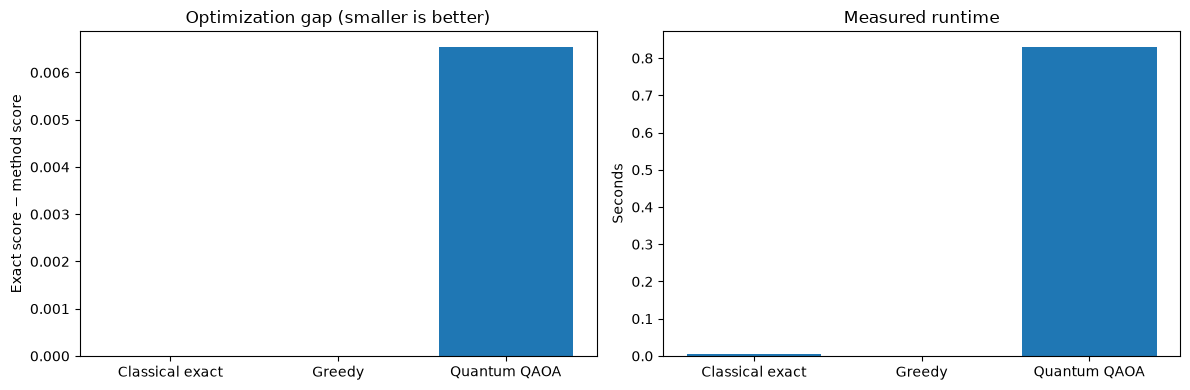

In [9]:
def jan_return(indices):
    return float(np.mean(actual_jan[list(indices)]))

results = pd.DataFrame([
    {"Method": "Classical exact", "ETFs": ", ".join(portfolio_names(classical_choice)), "Score": classical_score, "Seconds": classical_time, "Jan 2025 return": jan_return(classical_choice)},
    {"Method": "Greedy", "ETFs": ", ".join(portfolio_names(greedy_choice)), "Score": portfolio_score(greedy_choice), "Seconds": greedy_time, "Jan 2025 return": jan_return(greedy_choice)},
    {"Method": "Quantum QAOA", "ETFs": ", ".join(portfolio_names(quantum_choice)), "Score": quantum_score, "Seconds": qaoa_time, "Jan 2025 return": jan_return(quantum_choice)},
])
results["Gap from exact"] = classical_score - results["Score"]
print(results.round(6).to_string(index=False))
results.to_csv("quantum_vs_classical_20_etfs.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(results["Method"], results["Gap from exact"])
axes[0].set_title("Optimization gap (smaller is better)")
axes[0].set_ylabel("Exact score − method score")
axes[1].bar(results["Method"], results["Seconds"])
axes[1].set_title("Measured runtime")
axes[1].set_ylabel("Seconds")
plt.tight_layout()
plt.show()

In [10]:
print("CLASSICAL RESULTS")
print("-------------------")
print("Best Portfolio:", classical_choice)
print("Best Score:", round(classical_score, 6))
print("Runtime:", round(classical_time, 5), "seconds")

print("\nGREEDY RESULTS")
print("-------------------")
print("Portfolio:", greedy_choice)
print("Score:", round(portfolio_score(greedy_choice), 6))
print("Runtime:", round(greedy_time, 5), "seconds")

CLASSICAL RESULTS
-------------------
Best Portfolio: (2, 3, 6)
Best Score: 0.043425
Runtime: 0.00648 seconds

GREEDY RESULTS
-------------------
Portfolio: (2, 3, 6)
Score: 0.043425
Runtime: 0.00051 seconds


In [15]:
# First test with 3 seeds

DEPTH = 1

results = []

for seed in [1, 11]:

    run = run_qaoa_trial(
        seed=seed,
        depth=DEPTH,
        max_iter=30
    )

    results.append(run)

    print("Finished seed:", seed)

qaoa_results = pd.DataFrame(results)

display(qaoa_results)

Finished seed: 1
Finished seed: 11


,seed,depth,score,gap,found_optimum,runtime,valid_shots,optimizer_calls,portfolio
0,1,1,0.029125,0.014301,False,1.450155,1024,20,"XLF, XLP, SLV"
1,11,1,0.029125,0.014301,False,1.416362,1024,21,"XLF, XLP, SLV"


In [16]:
all_results = []

for depth in [1, 2]:

    DEPTH = depth

    for seed in range(1, 11):

        run = run_qaoa_trial(
            seed=seed,
            depth=depth,
            max_iter=50
        )

        all_results.append(run)

        print("Depth:", depth, "Seed:", seed, "Done")

comparison = pd.DataFrame(all_results)

display(comparison)

Depth: 1 Seed: 1 Done
Depth: 1 Seed: 2 Done
Depth: 1 Seed: 3 Done
Depth: 1 Seed: 4 Done
Depth: 1 Seed: 5 Done
Depth: 1 Seed: 6 Done
Depth: 1 Seed: 7 Done
Depth: 1 Seed: 8 Done
Depth: 1 Seed: 9 Done
Depth: 1 Seed: 10 Done
Depth: 2 Seed: 1 Done
Depth: 2 Seed: 2 Done
Depth: 2 Seed: 3 Done
Depth: 2 Seed: 4 Done
Depth: 2 Seed: 5 Done
Depth: 2 Seed: 6 Done
Depth: 2 Seed: 7 Done
Depth: 2 Seed: 8 Done
Depth: 2 Seed: 9 Done
Depth: 2 Seed: 10 Done


,seed,depth,score,gap,found_optimum,runtime,valid_shots,optimizer_calls,portfolio
0,1,1,0.029125,0.014301,False,1.345351,1024,20,"XLF, XLP, SLV"
1,2,1,0.036882,0.006543,False,1.196968,1024,17,"XLF, XLU, SLV"
2,3,1,0.036882,0.006543,False,0.895863,1024,13,"XLF, XLU, SLV"
3,4,1,0.029125,0.014301,False,1.202093,1024,19,"XLF, XLP, SLV"
4,5,1,0.036882,0.006543,False,1.241905,1024,18,"XLF, XLU, SLV"
5,6,1,0.029125,0.014301,False,1.296678,1024,18,"XLF, XLP, SLV"
6,7,1,0.029125,0.014301,False,1.548083,1024,21,"XLF, XLP, SLV"
7,8,1,0.029125,0.014301,False,1.105975,1024,18,"XLF, XLP, SLV"
8,9,1,0.029125,0.014301,False,1.041168,1024,15,"XLF, XLP, SLV"
9,10,1,0.029125,0.014301,False,1.539505,1024,22,"XLF, XLP, SLV"


In [17]:
summary = comparison.groupby("depth").agg(
    average_score=("score", "mean"),
    average_gap=("gap", "mean"),
    optimal_rate=("found_optimum", "mean"),
    average_runtime=("runtime", "mean"),
    average_valid_shots=("valid_shots", "mean")
)

summary["optimal_rate"] = summary["optimal_rate"] * 100

print("QAOA Experiment Summary")
display(summary.round(4))

print("Classical optimal score:", round(classical_score, 6))
print("Classical runtime:", round(classical_time, 6))
print("Greedy runtime:", round(greedy_time, 6))

QAOA Experiment Summary


,average_score,average_gap,optimal_rate,average_runtime,average_valid_shots
depth,,,,,
1,0.0315,0.0120,0.0,1.2414,1024.0
2,0.0367,0.0068,0.0,3.3555,1024.0


Classical optimal score: 0.043425
Classical runtime: 0.006479
Greedy runtime: 0.000515


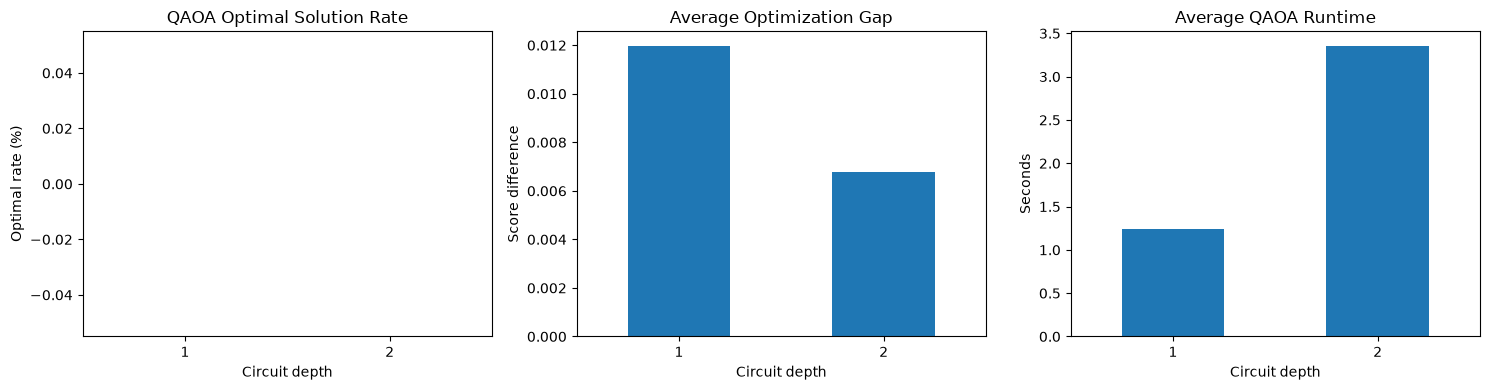

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

summary["optimal_rate"].plot(
    kind="bar",
    ax=axes[0],
    title="QAOA Optimal Solution Rate"
)
axes[0].set_ylabel("Optimal rate (%)")

summary["average_gap"].plot(
    kind="bar",
    ax=axes[1],
    title="Average Optimization Gap"
)
axes[1].set_ylabel("Score difference")

summary["average_runtime"].plot(
    kind="bar",
    ax=axes[2],
    title="Average QAOA Runtime"
)
axes[2].set_ylabel("Seconds")

for ax in axes:
    ax.set_xlabel("Circuit depth")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("qaoa_experiment_results.png", dpi=150)
plt.show()

In [19]:
from pathlib import Path

Path("results").mkdir(exist_ok=True)

comparison.to_csv("results/qaoa_trials.csv", index=False)
summary.to_csv("results/qaoa_summary.csv")

print("Results saved")
plt.savefig("results/qaoa_experiment_results.png", dpi=150)

Results saved


<Figure size 640x480 with 0 Axes>

## 7. How to describe the results

- **Exact classical optimization** checks all 1,140 combinations and is the reference answer for the fixed score function.
- **Greedy** is a fast heuristic and may return a lower score.
- **QAOA** is a randomized quantum-circuit simulation. Record whether it matched the optimum, its absolute score gap, feasible samples, and runtime.
- For research on **optimal solution rate**, rerun the QAOA experiment across different seeds and multiple decision dates. One run cannot estimate a success probability.
- For a **Sharpe ratio comparison**, extend to a multi-month walk-forward backtest and run a paired block bootstrap on the matched monthly strategy returns. Do not report a Sharpe-significance test from one month.
- Compare computational time carefully: classical exhaustive-search Python runtime is **not** directly comparable to physical quantum-hardware speed. This only measures the costs of the implementations tested here.

### Settings to report

20 ETFs; choose 3 equally weighted; 1,140 portfolios; expected monthly returns from Random Forest; monthly covariance from 2022–2024; risk aversion `LAMBDA=1.0`; XY constraint-preserving mixer; QAOA `DEPTH`, `SHOTS`, `MAX_ITER`, random seed; final portfolio is highest-scoring valid sampled bitstring; adjusted ETF price source: Yahoo Finance via yfinance.

### Related research

For your literature review, investigate Brandhofer et al., *Benchmarking the Performance of Portfolio Optimization with QAOA* (2023), and the IBM Qiskit Aer guides. This notebook is a simplified implementation, not a direct replication of those papers.